In [37]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import xarray as xr
import geopandas as gpd
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path


# --- File paths ---
file_site_cla = "../data/raw/nfi/site_cla.csv"
file_stand_waa = "../data/raw/nfi/stand_waa.csv"
file_tree_baa = "../data/raw/nfi/tree_baa.csv"

PROCESSED_NFI_FILE_PATH = Path("../data/preprocessed/nfi/nfi_processed_data.csv")
PROCESSED_NFI_FILE_PATH.parent.mkdir(parents=True, exist_ok=True)

RAW_CH2018_FILEPATH = "../data/raw/ch2018/CH2018_pr_KNMI-RACMO_ECEARTH_EUR44_RCP85_QMgrid_1981-2099.nc"

SAMPLE_2018_FILE_PATH = "../data/preprocessed/ch2018/CH2018_ensemble_mean_pr_RCP26.csv"
CLOSEST_COORDS_FILE_PATH = "../data/preprocessed/NFI_CH2018_closest_coords.csv"



In [38]:
# Reads the three raw NFI data files and displays a preview and shape for each

df_site_cla = pd.read_csv(file_site_cla)
df_stand_waa = pd.read_csv(file_stand_waa)
df_tree_baa = pd.read_csv(file_tree_baa)

print("--- site_cla.csv ---")
print(df_site_cla.head()) 
print(f"Shape: {df_site_cla.shape}\n") 

print("--- stand_waa.csv ---")
print(df_stand_waa.head())
print(f"Shape: {df_stand_waa.shape}\n")

print("--- tree_baa.csv ---")
print(df_tree_baa.head())
print(f"Shape: {df_tree_baa.shape}\n")


--- site_cla.csv ---
        CLNR         X         Y    ASPECT25    SLOPE25    Z25    PH  GWL3  \
0    1     4  685000.0  295000.0  172.848160  39.759354  735.9  7.01  3324   
1    2     6  686000.0  295000.0  104.901916  31.302792  744.3  7.21  5217   
2    3     7  687000.0  295000.0  125.188889  28.632330  715.4   NaN  3339   
3    4     9  688000.0  295000.0  152.808624  26.588442  730.6   NaN  3818   
4    5    10  691000.0  295000.0   25.997786  11.292724  612.1  3.95  4730   

   NAISHSTKOMB  NAISHSTKOMB3KL  NAISWFORM20  
0            5               2           -1  
1            5               2            1  
2            5               2           -1  
3            5               2           -1  
4            4               2           -1  
Shape: (41279, 12)

--- stand_waa.csv ---
        CLNR  INVNR  BASFPH  BESTALTKLA20  BFANTNDHKLA  DDOM  BEWIRTINT1  EST  \
0    1     6    150   23.85             6            1  45.2           1    3   
1    2     6    250   48.99   

In [39]:
# Take the desired columns of stand_waa

desired_columns = ["CLNR", "DATUMF","INVNR","BASFPH","BEWIRTINT1"]

stand_df = df_stand_waa[desired_columns].copy()

print(stand_df.head())
print(f"Shape: {stand_df.shape}\n")

   CLNR      DATUMF  INVNR  BASFPH  BEWIRTINT1
0     6  16.04.1984    150   23.85           1
1     6  19.10.1994    250   48.99           2
2     6  01.11.2005    350   37.91           1
3     6  24.04.2015    450   15.73           1
4     6  23.10.2024    550   12.09          -1
Shape: (20820, 5)



In [40]:
# Statistical summary of the BASFPH column

print("BASFPH statistics:")
print(stand_df["BASFPH"].describe())

BASFPH statistics:
count    20820.000000
mean        31.877350
std         19.672473
min          0.000000
25%         18.220000
50%         30.120000
75%         42.910000
max        336.360000
Name: BASFPH, dtype: float64


In [41]:
# Investigates and summarizes records where the basal area (BASFPH) is zero

zero_basfph_df = stand_df[stand_df['BASFPH'] == 0]

print("--- Overview of plots (CLNR) and inventories (INVNR) with BASFPH = 0 ---")
print(zero_basfph_df[['CLNR', 'INVNR', 'BASFPH']].head(10))

print(f"\nTotal number of records with BASFPH = 0: {len(zero_basfph_df)}")

print("\n--- Distribution of records with BASFPH = 0 by INVNR ---")
print(zero_basfph_df['INVNR'].value_counts().sort_index())

unique_clnr_count = zero_basfph_df['CLNR'].nunique()
print(f"\nNumber of unique CLNR values with BASFPH = 0: {unique_clnr_count}")

--- Overview of plots (CLNR) and inventories (INVNR) with BASFPH = 0 ---
     CLNR  INVNR  BASFPH
30    151    150     0.0
34    151    550     0.0
80    448    150     0.0
135   636    150     0.0
136   636    250     0.0
201  1178    250     0.0
202  1178    350     0.0
208  1182    450     0.0
215  1194    150     0.0
231  1218    250     0.0

Total number of records with BASFPH = 0: 530

--- Distribution of records with BASFPH = 0 by INVNR ---
INVNR
150    131
250    111
350    120
450     99
550     69
Name: count, dtype: int64

Number of unique CLNR values with BASFPH = 0: 357


In [42]:
# Check number of rows of different management types (BEWIRTINT1)

bewirtint1_count = stand_df[stand_df['BEWIRTINT1'] == 1].shape[0]
print(f"\nNumber of rows with BEWIRTINT1 = 1: {bewirtint1_count}")


Number of rows with BEWIRTINT1 = 1: 13129


In [43]:
# Check for duplicates in CLNR in df_site_cla

df_site_cla["CLNR"].duplicated().any() #Check for duplicates in CLNR in df_site_cla

np.False_

In [44]:
# Selects and displays relevant columns from the site data

desired_columns = ["CLNR","ASPECT25", "SLOPE25","PH","Z25","X","Y","NAISHSTKOMB"]

site_df = df_site_cla[desired_columns].copy()

print(site_df.head())
print(f"Shape: {site_df.shape}\n")

   CLNR    ASPECT25    SLOPE25    PH    Z25         X         Y  NAISHSTKOMB
0     4  172.848160  39.759354  7.01  735.9  685000.0  295000.0            5
1     6  104.901916  31.302792  7.21  744.3  686000.0  295000.0            5
2     7  125.188889  28.632330   NaN  715.4  687000.0  295000.0            5
3     9  152.808624  26.588442   NaN  730.6  688000.0  295000.0            5
4    10   25.997786  11.292724  3.95  612.1  691000.0  295000.0            4
Shape: (41279, 8)



In [45]:
# Merge stand_df with df_site_cla based on CLNR


stand_site_df = pd.merge(left=stand_df, right = site_df, how= "left") #left join because the site_df also contains CLNR from non forest patches. merge on CLNR

print(stand_site_df.head())
print(f"Shape: {stand_site_df.shape}\n")

   CLNR      DATUMF  INVNR  BASFPH  BEWIRTINT1    ASPECT25    SLOPE25    PH  \
0     6  16.04.1984    150   23.85           1  104.901916  31.302792  7.21   
1     6  19.10.1994    250   48.99           2  104.901916  31.302792  7.21   
2     6  01.11.2005    350   37.91           1  104.901916  31.302792  7.21   
3     6  24.04.2015    450   15.73           1  104.901916  31.302792  7.21   
4     6  23.10.2024    550   12.09          -1  104.901916  31.302792  7.21   

     Z25         X         Y  NAISHSTKOMB  
0  744.3  686000.0  295000.0            5  
1  744.3  686000.0  295000.0            5  
2  744.3  686000.0  295000.0            5  
3  744.3  686000.0  295000.0            5  
4  744.3  686000.0  295000.0            5  
Shape: (20820, 12)



In [46]:
# Check for nan values in the merged DataFrame
columns_with_nan = stand_site_df.isnull().any()

print("\nColumns containing NaN values:")
print(columns_with_nan[columns_with_nan == True].index.tolist()) #  print the names of the columns with NaN values


nan_counts_per_column = stand_site_df.isnull().sum()

print("\nNumber of NaN values per column:")
print(nan_counts_per_column[nan_counts_per_column > 0])

nan_rows = stand_site_df[stand_site_df.isnull().any(axis=1)][["CLNR", "INVNR"]]
print("\nRows with NaN values in any column:")
print(nan_rows)

print(f"\nNumber of different CLNR with NaN values: {nan_rows['CLNR'].nunique()}")
# 77 CLNRs * 5 inventories = 385: each NaN CLNR is NaN in every inventory.

stand_site_df = stand_site_df.dropna()
print(stand_site_df.shape)



Columns containing NaN values:
['ASPECT25', 'PH']

Number of NaN values per column:
ASPECT25      5
PH          380
dtype: int64

Rows with NaN values in any column:
         CLNR  INVNR
1120     8030    150
1121     8030    250
1122     8030    350
1123     8030    450
1124     8030    550
...       ...    ...
19630  153527    150
19631  153527    250
19632  153527    350
19633  153527    450
19634  153527    550

[385 rows x 2 columns]

Number of different CLNR with NaN values: 77
(20435, 12)


In [47]:
# Filters the raw tree data to include only trees that are alive and standing

# Count only standing living trees (IPOPSTE==1), incl. IPOPLEB==-1 (not measured); the IPOPSTE==-1 & IPOPLEB==1 case never occurs.

mask_alive_and_standing = ((df_tree_baa['IPOPLEB'] == 1) | (df_tree_baa['IPOPLEB'] == -1)) & (df_tree_baa['IPOPSTE'] == 1) 
df_alive_standing_trees = df_tree_baa[mask_alive_and_standing].copy() 

print("--- Alive and Standing Trees (df_alive_standing_trees) ---")
print(df_alive_standing_trees.head())
print(f"Shape of alive and standing trees: {df_alive_standing_trees.shape}\n")


--- Alive and Standing Trees (df_alive_standing_trees) ---
        CLNR   BANR  INVNR  BART  D13      BASF    BAL  RPSTZ  IPOPBAUM  \
0    1     4  79312    150    50   16  0.020106  14.22   50.0         1   
1    2     4  79313    150    10   21  0.034636   7.37   50.0         1   
2    3     4  79314    150    10   20  0.031416   9.10   50.0         1   
3    4     4  79315    150    10   17  0.022698  11.95   50.0         1   
4    5     4  79316    150    10   13  0.013273  17.00   50.0         1   

   IPOPLEB  IPOPTOT  IPOPLIE  IPOPSTE  
0       -1       -1        0        1  
1       -1       -1        0        1  
2       -1       -1        0        1  
3       -1       -1        0        1  
4       -1       -1        0        1  
Shape of alive and standing trees: (385309, 14)



In [48]:
# Take the desired columns of the filtered tree_baa dataframe

desired_columns = ["CLNR","BANR","INVNR","BART","BASF","RPSTZ"]

tree_df_prefiltered = df_alive_standing_trees[desired_columns].copy()

print(tree_df_prefiltered.head())
print(f"Shape: {tree_df_prefiltered.shape}\n")

   CLNR   BANR  INVNR  BART      BASF  RPSTZ
0     4  79312    150    50  0.020106   50.0
1     4  79313    150    10  0.034636   50.0
2     4  79314    150    10  0.031416   50.0
3     4  79315    150    10  0.022698   50.0
4     4  79316    150    10  0.013273   50.0
Shape: (385309, 6)



In [49]:
# Delete unnecessary rows in df_tree_baa. Only include plots (CLNRs) that exist in the cleaned stand_site_df.
valid_clnrs = stand_site_df['CLNR'].unique()
print(f"Number of unique CLNRs in stand_site_df: {len(valid_clnrs)}")

tree_df = tree_df_prefiltered[tree_df_prefiltered['CLNR'].isin(valid_clnrs)].copy() #df[boolean series] => outputs rows in df that are True

print(tree_df.head())
print(f"Shape of original df_tree_baa: {tree_df_prefiltered.shape}")
print(f"Shape of filtered df_tree_baa: {tree_df.shape}\n")

Number of unique CLNRs in stand_site_df: 4087
    CLNR   BANR  INVNR  BART      BASF  RPSTZ
16     6  79831    150    50  0.080425   50.0
17     6  79832    150    60  0.246301   20.0
18     6  79833    150    50  0.070686   50.0
19     6  79834    150    50  0.125664   20.0
20     6  79835    150    50  0.159043   20.0
Shape of original df_tree_baa: (385309, 6)
Shape of filtered df_tree_baa: (232510, 6)



In [50]:
# Check for any remaining nan in tree_df

columns_with_nan = tree_df.isnull().any()

print("\nColumns containing NaN values:")
print(columns_with_nan[columns_with_nan == True].index.tolist())




Columns containing NaN values:
[]


In [51]:
# Calculates the basal area per hectare for each individual tree (BASFPHS)

tree_df['BASFPHS'] = tree_df['BASF'] * tree_df['RPSTZ']

print(tree_df.head())
print(f"Shape of tree_df: {tree_df.shape}\n") 

print("Data types of relevant columns:")
print(tree_df[['BASF', 'RPSTZ', 'BASFPHS']].dtypes)

    CLNR   BANR  INVNR  BART      BASF  RPSTZ   BASFPHS
16     6  79831    150    50  0.080425   50.0  4.021238
17     6  79832    150    60  0.246301   20.0  4.926017
18     6  79833    150    50  0.070686   50.0  3.534292
19     6  79834    150    50  0.125664   20.0  2.513274
20     6  79835    150    50  0.159043   20.0  3.180863
Shape of tree_df: (232510, 7)

Data types of relevant columns:
BASF       float64
RPSTZ      float64
BASFPHS    float64
dtype: object


In [52]:
# Aggregates the individual tree data by summing the basal area per species for each plot, inventory and tree species (BART).

grouping_cols = ['CLNR', 'INVNR', 'BART']

aggregated_tree_df = tree_df.groupby(grouping_cols)['BASFPHS'].sum().reset_index()

print("--- Aggregated tree_df ---")
print(aggregated_tree_df.head(10))
print(f"Shape of aggregated_tree_df: {aggregated_tree_df.shape}\n")



--- Aggregated tree_df ---
   CLNR  INVNR  BART    BASFPHS
0     6    150    50  18.924954
1     6    150    60   4.926017
2     6    250    15   6.560779
3     6    250    50  41.150547
4     6    250    81   1.276968
5     6    350    15   6.560779
6     6    350    50  29.078607
7     6    350    81   2.270166
8     6    450    15   7.761087
9     6    450    50   7.964777
Shape of aggregated_tree_df: (50926, 4)



In [53]:
# Classifies each tree species (BART) into Broadleaf (HW) or Conifer (SW) categories
# Source: https://www.dora.lib4ri.ch/wsl/islandora/object/wsl%3A23637/datastream/PDF/D%C3%BCggelin-2020-Schweizerisches_Landesforstinventar._Anleitung_f%C3%BCr_die-%28published_version%29.pdf
softwood_codes = [11, 30, 31, 32, 33, 146, 147, 34, 10, 35, 19, 18, 16, 36, 17, 15, 22, 37, 25, 38, 39]

hardwood_codes = [301, 56, 302, 59, 57, 58, 89, 161, 63, 64, 65, 66, 67, 62, 68, 162, 322, 50, 60, 61, 69, 90, 324, 71, 70, 303, 163, 150, 74, 76, 75, 149, 77, 321, 72, 54, 52, 53, 51, 55, 191, 78, 79, 152, 80, 81, 82, 83, 159, 158, 84, 85, 86, 88, 160, 87]
def get_wood_type(bart_code):
    if bart_code in softwood_codes:
        return 'SW'
    elif bart_code in hardwood_codes:
        return 'HW'

aggregated_tree_df['Wood_Type'] = aggregated_tree_df['BART'].apply(get_wood_type)

print("--- aggregated_tree_df with Wood_Type ---")
print(aggregated_tree_df.head())
print(f"Shape: {aggregated_tree_df.shape}\n")

--- aggregated_tree_df with Wood_Type ---
   CLNR  INVNR  BART    BASFPHS Wood_Type
0     6    150    50  18.924954        HW
1     6    150    60   4.926017        HW
2     6    250    15   6.560779        SW
3     6    250    50  41.150547        HW
4     6    250    81   1.276968        HW
Shape: (50926, 5)



In [54]:
# Aggregates and pivots the data to create separate columns for total HW and SW basal area per plot-inventory

basfphs_sum_by_wood_type = aggregated_tree_df.groupby(['CLNR', 'INVNR', 'Wood_Type'])['BASFPHS'].sum().reset_index() #agregate the HW and SW so per CLNR and INVNR we dont have multiple rows for SW or HW

pivoted_wood_types = basfphs_sum_by_wood_type.pivot_table(
    index=['CLNR', 'INVNR'],
    columns='Wood_Type',
    values='BASFPHS',
    fill_value=0 # Fill NaN values with 0
).reset_index()

pivoted_wood_types.columns.name = None # Remove the name of the column index

print(pivoted_wood_types.head())
print(f"Shape: {pivoted_wood_types.shape}\n")


   CLNR  INVNR         HW        SW
0     6    150  23.850971  0.000000
1     6    250  42.427515  6.560779
2     6    350  31.348772  6.560779
3     6    450   7.964777  7.761087
4     6    550   7.908726  4.183128
Shape: (19721, 4)



In [55]:
# Calculates the total basal area by summing the HW and SW columns for later validation.

pivoted_wood_types["BASFPH_calculated"] =pivoted_wood_types["HW"] + pivoted_wood_types["SW"]
print(pivoted_wood_types.head(5))
print(f"Shape: {pivoted_wood_types.shape}")

   CLNR  INVNR         HW        SW  BASFPH_calculated
0     6    150  23.850971  0.000000          23.850971
1     6    250  42.427515  6.560779          48.988294
2     6    350  31.348772  6.560779          37.909552
3     6    450   7.964777  7.761087          15.725865
4     6    550   7.908726  4.183128          12.091854
Shape: (19721, 5)


In [56]:
# Compares plot-inventories between the stand_site and aggregated tree dataframes

stand_site_df['plot_inv_id'] = stand_site_df['CLNR'].astype(str) + "_" + stand_site_df['INVNR'].astype(str)
pivoted_wood_types['plot_inv_id'] = pivoted_wood_types['CLNR'].astype(str) + "_" + pivoted_wood_types['INVNR'].astype(str)

ids_in_stand_site = set(stand_site_df['plot_inv_id'])
ids_in_pivoted = set(pivoted_wood_types['plot_inv_id'])

# IDs in stand_site_df but not in pivoted_wood_types (missing in one direction only).
missing_ids_from_pivoted =  ids_in_stand_site - ids_in_pivoted # the other way are 0 values

print(f"Number of plot-inventories in stand_site_df: {len(ids_in_stand_site)}")
print(f"Number of plot-inventories in pivoted_wood_types: {len(ids_in_pivoted)}")
print(f"Number of plot-inventories in stand_site_df but NOT in pivoted_wood_types: {len(missing_ids_from_pivoted)}")


missing_plot_inventories_df = stand_site_df[stand_site_df['plot_inv_id'].isin(missing_ids_from_pivoted)]
print("\n--- Details of plot-inventories present in stand_site_df but missing from pivoted_wood_types ---")
print(missing_plot_inventories_df.head())
print(f"Shape of missing_plot_inventories_df: {missing_plot_inventories_df.shape}")
print("\nBASFPH values for these missing plot-inventories (from stand_waa):")
print(missing_plot_inventories_df['BASFPH'].describe())

# BASFPH is 0 in all these cases (no tree data), so drop these rows from stand_site_df.

stand_site_df.drop(columns=['plot_inv_id'], inplace=True)
pivoted_wood_types.drop(columns=['plot_inv_id'], inplace=True)


Number of plot-inventories in stand_site_df: 20435
Number of plot-inventories in pivoted_wood_types: 19721
Number of plot-inventories in stand_site_df but NOT in pivoted_wood_types: 714

--- Details of plot-inventories present in stand_site_df but missing from pivoted_wood_types ---
     CLNR      DATUMF  INVNR  BASFPH  BEWIRTINT1    ASPECT25    SLOPE25    PH  \
30    151  18.03.1985    150     0.0           1  325.784515   4.534816  3.50   
34    151  30.03.2021    550     0.0           1  325.784515   4.534816  3.50   
80    448  29.03.1984    150     0.0           1  256.538849  19.331051  7.03   
135   636  23.03.1984    150     0.0           1  306.273499  47.072559  6.91   
136   636  15.03.1994    250     0.0           1  306.273499  47.072559  6.91   

       Z25         X         Y  NAISHSTKOMB plot_inv_id  
30   649.0  692000.0  291000.0            7     151_150  
34   649.0  692000.0  291000.0            7     151_550  
80   570.1  680000.0  287000.0            7     448_150

In [57]:
# Creates the final NFI dataframe by merging the stand/site data with the aggregated HW/SW data

print(f"Shape of stand_site_df before merge: {stand_site_df.shape}")
print(f"Shape of pivoted_wood_types before merge: {pivoted_wood_types.shape}")

# An 'inner' join is the most direct way to keep only the rows that match in both dataframes.
NFI_df = pd.merge(
    left=stand_site_df,
    right=pivoted_wood_types,
    on=['CLNR', 'INVNR'],
    how='inner'
)

print("\n--- Final Merged DataFrame ---")
print(NFI_df.head(10))
print(f"Shape of final NFI_df: {NFI_df.shape}\n")

    

Shape of stand_site_df before merge: (20435, 12)
Shape of pivoted_wood_types before merge: (19721, 5)

--- Final Merged DataFrame ---
   CLNR      DATUMF  INVNR  BASFPH  BEWIRTINT1    ASPECT25    SLOPE25    PH  \
0     6  16.04.1984    150   23.85           1  104.901916  31.302792  7.21   
1     6  19.10.1994    250   48.99           2  104.901916  31.302792  7.21   
2     6  01.11.2005    350   37.91           1  104.901916  31.302792  7.21   
3     6  24.04.2015    450   15.73           1  104.901916  31.302792  7.21   
4     6  23.10.2024    550   12.09          -1  104.901916  31.302792  7.21   
5    26  10.04.1984    150   30.12           1  345.627380  16.516918  6.44   
6    26  19.10.1994    250   26.78           1  345.627380  16.516918  6.44   
7    26  01.11.2005    350   21.50           1  345.627380  16.516918  6.44   
8    26  07.04.2010    450   25.43           1  345.627380  16.516918  6.44   
9    26  08.05.2018    550   28.77           1  345.627380  16.516918  6.44 

In [58]:
# Defines an optional, stricter data cleaning method that is currently disabled
STRICTER_METHOD = False

if STRICTER_METHOD:

    missing_clnrs_df = stand_site_df[stand_site_df['plot_inv_id'].isin(missing_ids_from_pivoted)]
    clnrs_to_remove = missing_clnrs_df['CLNR'].unique()

    print(f"Found {len(clnrs_to_remove)} CLNRs with at least one missing inventory. These plots will be removed entirely.")

    stand_site_df_filtered = stand_site_df[~stand_site_df['CLNR'].isin(clnrs_to_remove)].copy()

    stand_site_df_filtered.drop(columns='plot_inv_id', inplace=True)
    pivoted_wood_types.drop(columns='plot_inv_id', inplace=True)

    NFI_df_strict = pd.merge(
        stand_site_df_filtered,
        pivoted_wood_types,
        on=['CLNR', 'INVNR'],
        how='inner' # Inner join is still safest
    )

    print("\n--- Final Merged DataFrame (Strict Method) ---")
    print(f"Shape of final NFI_df_strict: {NFI_df_strict.shape}\n")

In [59]:
# Compares the original BASFPH with the calculated value, analyzing the mismatches and their distribution. Diagnostic cell.

# Mismatches are expected: BASFPH_calculated only includes trees categorized as SW or HW.

print("\n--- Comparing BASFPH (from stand_waa) with BASFPH_calculated (from tree_baa) ---")

NFI_df['BASFPH_calculated_rounded'] = NFI_df['BASFPH_calculated'].round(2)

NFI_df['difference'] = (NFI_df['BASFPH'] - NFI_df['BASFPH_calculated_rounded']).abs()

total_rows = len(NFI_df)
mismatched_rows_df = NFI_df[NFI_df['difference'] > 0.001] # Use a small threshold to avoid float precision issues
num_mismatches = len(mismatched_rows_df)
num_matches = total_rows - num_mismatches

print(f"Total rows compared: {total_rows}")
print(f"Number of matching rows: {num_matches}")
print(f"Number of mismatched rows: {num_mismatches}")
if total_rows > 0:
    print(f"Mismatch rate: {num_mismatches/total_rows:.2%}")


# Large mismatches (difference > 1.0).
print("\n--- Analyzing Large Mismatches (Absolute Difference > 1.0) ---")

large_mismatch_df = NFI_df[NFI_df['difference'] > 1.0].copy()

print(f"\nFound {len(large_mismatch_df)} rows where the absolute difference is > 1.0.")

if not large_mismatch_df.empty:
    print("\nTop 20 largest mismatches (sorted by difference):")
    display_cols = ['CLNR', 'INVNR', 'BASFPH', 'BASFPH_calculated', 'difference']
    print(large_mismatch_df[display_cols].sort_values('difference', ascending=False).head(20))

    print("\nStatistics for these large differences (>1.0):")
    print(large_mismatch_df['difference'].describe())

    print("\nNumber of large mismatches (>1.0) per INVNR:")
    print(large_mismatch_df['INVNR'].value_counts())
    
    NFI_df.drop(columns=['BASFPH_calculated_rounded'], inplace=True)
    NFI_df.drop(columns=['difference'], inplace=True)
    
else:
    print("No mismatches with a difference greater than 1.0 were found.")

NFI_df.drop(columns=['BASFPH_calculated'], inplace=True)


--- Comparing BASFPH (from stand_waa) with BASFPH_calculated (from tree_baa) ---
Total rows compared: 19721
Number of matching rows: 17818
Number of mismatched rows: 1903
Mismatch rate: 9.65%

--- Analyzing Large Mismatches (Absolute Difference > 1.0) ---

Found 1543 rows where the absolute difference is > 1.0.

Top 20 largest mismatches (sorted by difference):
         CLNR  INVNR  BASFPH  BASFPH_calculated  difference
18370  152068    250   75.37           8.169329       67.20
18369  152068    150   71.36           5.492460       65.87
17666  147290    250   66.33           2.724514       63.61
14195  112307    250   57.08           1.417643       55.66
10609   77386    150   60.97          11.224911       49.75
14194  112307    150   53.63           4.060509       49.57
10774   78580    250   54.92           7.744026       47.18
18801  155343    250   51.42           6.440265       44.98
18388  152140    250   47.38           2.905973       44.47
18266  151485    250   52.74       

In [60]:
# Creates target variable by adding the basal area of the next inventory period (BASFPH_next_INVNR)

NFI_df.sort_values(by=['CLNR', 'INVNR'], inplace=True)

NFI_df['BASFPH_next_INVNR'] = NFI_df.groupby('CLNR')['BASFPH'].shift(-1)

print("\n--- NFI_df with BASFPH from next INVNR (first 15 rows) ---")
print(NFI_df[['CLNR', 'INVNR', 'BASFPH', 'BASFPH_next_INVNR']].head(15))

NFI_df["BASFPH_difference"] = NFI_df["BASFPH"] - NFI_df["BASFPH_next_INVNR"]

NFI_df.shape


--- NFI_df with BASFPH from next INVNR (first 15 rows) ---
    CLNR  INVNR  BASFPH  BASFPH_next_INVNR
0      6    150   23.85              48.99
1      6    250   48.99              37.91
2      6    350   37.91              15.73
3      6    450   15.73              12.09
4      6    550   12.09                NaN
5     26    150   30.12              26.78
6     26    250   26.78              21.50
7     26    350   21.50              25.43
8     26    450   25.43              28.77
9     26    550   28.77                NaN
10    47    150   63.62              58.50
11    47    250   58.50              57.98
12    47    350   57.98              46.04
13    47    450   46.04              38.12
14    47    550   38.12                NaN


(19721, 16)

In [61]:
# Calculates the Broadleaf Fraction (HWSW_prop) and creates the second target variable for this fraction in the next inventory
total_wood = NFI_df["HW"] + NFI_df["SW"]
NFI_df['HWSW_prop'] = np.divide(NFI_df['HW'], total_wood)
NFI_df['HWSW_prop'].fillna(0.5, inplace=True) # If both HW and SW are 0, assume a neutral 0.5 proportion. 0 cases


# Sort by plot and inventory year to ensure the 'next' value is correct
NFI_df.sort_values(by=['CLNR', 'INVNR'], inplace=True) 

NFI_df['HWSW_prop_next_INVNR'] = NFI_df.groupby('CLNR')['HWSW_prop'].shift(-1) # We do groupby to ensure we only shift within each plot

# Last entry per plot gets NaN (expected; dropped later).
print("New target column created.")
print("Example of a single plot (CLNR) to verify:")
print(NFI_df[NFI_df['CLNR'] == 6][['CLNR', 'INVNR', 'HWSW_prop', 'HWSW_prop_next_INVNR']])

NFI_df.shape

New target column created.
Example of a single plot (CLNR) to verify:
   CLNR  INVNR  HWSW_prop  HWSW_prop_next_INVNR
0     6    150   1.000000              0.866075
1     6    250   0.866075              0.826936
2     6    350   0.826936              0.506476
3     6    450   0.506476              0.654054
4     6    550   0.654054                   NaN


(19721, 18)

In [62]:
# Calculates the time difference in years between consecutive inventories for each plot

NFI_df.sort_values(by=['CLNR', 'INVNR'], inplace=True)

NFI_df['DATUMF_dt'] = pd.to_datetime(NFI_df['DATUMF'], format='%d.%m.%Y', errors='coerce')

NFI_df['INVYR'] = NFI_df['DATUMF_dt'].dt.year
NFI_df['DATUMF_next_INVNR_dt'] = NFI_df.groupby('CLNR')['DATUMF_dt'].shift(-1)

NFI_df['Time_Diff_next_INVNR'] = NFI_df['DATUMF_next_INVNR_dt'] - NFI_df['DATUMF_dt']

NFI_df['Time_Diff_days'] = NFI_df['Time_Diff_next_INVNR'].dt.days
NFI_df['Time_Diff_years'] = NFI_df['Time_Diff_next_INVNR'].dt.days / 365.25

NFI_df['Time_Diff_years'] = NFI_df['Time_Diff_years'].round()

NFI_df.drop(columns=['DATUMF_dt', 'DATUMF_next_INVNR_dt','Time_Diff_next_INVNR','Time_Diff_days'], inplace=True, errors='ignore')

In [63]:
# Checks for and summarizes NaN values, which are expected in the newly created 'next_INVNR' columns

print(len(NFI_df[NFI_df['NAISHSTKOMB'] == -1]))
columns_with_nan = NFI_df.isnull().any()

print("Columns containing NaN values:")
print(columns_with_nan[columns_with_nan == True].index.tolist())

nan_counts_per_column = NFI_df.isnull().sum()

print("\nNumber of NaN values per column:")
print(nan_counts_per_column[nan_counts_per_column > 0])

rows_with_nan = NFI_df.isnull().any(axis=1).sum()
print(f"\nTotal rows containing at least one NaN value: {rows_with_nan}")
print(f"Total rows in DataFrame: {len(NFI_df)}")
print(f"Percentage of rows with NaN: {rows_with_nan/len(NFI_df)*100:.2f}%")

NFI_df.shape

0
Columns containing NaN values:
['BASFPH_next_INVNR', 'BASFPH_difference', 'HWSW_prop_next_INVNR', 'Time_Diff_years']

Number of NaN values per column:
BASFPH_next_INVNR       4081
BASFPH_difference       4081
HWSW_prop_next_INVNR    4081
Time_Diff_years         4081
dtype: int64

Total rows containing at least one NaN value: 4081
Total rows in DataFrame: 19721
Percentage of rows with NaN: 20.69%


(19721, 20)

In [64]:
# Adds a new feature: the squared value of the basal area
NFI_df['BASFPH_squared'] = NFI_df['BASFPH'] ** 2

In [65]:
# Cleans the management intensity column (BEWIRTINT1) by replacing -1 values and filling them
# Because for the iterative prediction we assume that BEWIRTINT1 is constant, we can also assume it in the training data.

print("processing BEWIRTINT1 -1 values...") 

print(f"Original value counts for BEWIRTINT1:\n{NFI_df['BEWIRTINT1'].value_counts().to_string()}")

NFI_df['BEWIRTINT1'] = NFI_df['BEWIRTINT1'].replace(-1, np.nan)

NFI_df['BEWIRTINT1'] = NFI_df.groupby('CLNR')['BEWIRTINT1'].ffill()
NFI_df['BEWIRTINT1'] = NFI_df.groupby('CLNR')['BEWIRTINT1'].bfill()

na_count = NFI_df['BEWIRTINT1'].isna().sum()

if na_count > 0:
    print(f"Warning: There are still {na_count} NaN values in 'BEWIRTINT1' after filling.")
    print("Rows with NaN values in 'BEWIRTINT1':")
    print(NFI_df[NFI_df['BEWIRTINT1'].isna()].head(10))  # Show first 10 rows with NaN values
    # its only one case: CLNR 161030
    NFI_df = NFI_df[NFI_df['BEWIRTINT1'].notna()] 
    
    
else:
    print("All NaN values in 'BEWIRTINT1' have been successfully filled.")


processing BEWIRTINT1 -1 values...
Original value counts for BEWIRTINT1:
BEWIRTINT1
 1    12377
 2     3094
 3     3077
-1     1173
Rows with NaN values in 'BEWIRTINT1':
         CLNR      DATUMF  INVNR  BASFPH  BEWIRTINT1    ASPECT25    SLOPE25  \
19430  161030  04.08.2023    550    2.27         NaN  137.580399  68.319237   

         PH      Z25         X  ...  NAISHSTKOMB   HW       SW  \
19430  6.77  1187.39  576000.0  ...            3  0.0  2.26823   

       BASFPH_next_INVNR  BASFPH_difference  HWSW_prop  HWSW_prop_next_INVNR  \
19430                NaN                NaN        0.0                   NaN   

       INVYR  Time_Diff_years  BASFPH_squared  
19430   2023              NaN          5.1529  

[1 rows x 21 columns]


In [66]:
# Check the year of the last inventory 

NFI_df[NFI_df['INVNR']== 450]['INVYR'].unique() 

array([2015, 2010, 2013, 2011, 2012, 2014, 2009], dtype=int32)

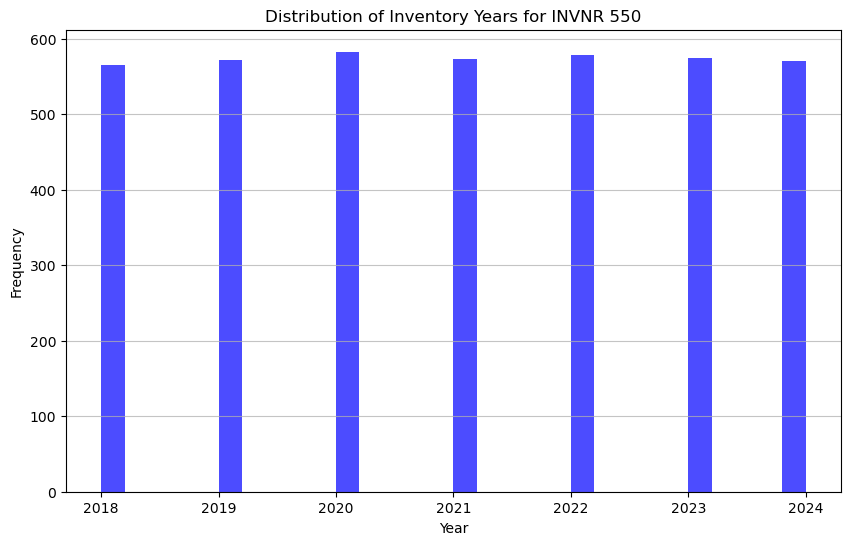

In [67]:
# Visualizes the distribution of inventory years for the final inventory period (INVNR=550)

plt.figure(figsize=(10, 6))
plt.hist(NFI_df[NFI_df['INVNR']== 550]['INVYR'], bins=30, color='blue', alpha=0.7)
plt.title('Distribution of Inventory Years for INVNR 550')
plt.xlabel('Year')
plt.ylabel('Frequency')
plt.grid(axis='y', alpha=0.75)
plt.show()

In [68]:
# Extrapolates the dataset with new rows for future inventories based on defined time steps.

# We will extrapolate from the final recorded inventory for each plot (INVNR=550)
last_records_df = NFI_df[NFI_df['INVNR'] == 550].copy() # the plots that dont have a final inventory (INVNR=550) will not be extrapolated
print(f"Found {len(last_records_df)} plots with a final inventory (INVNR=550) to extrapolate.")
print(f"Starting years for extrapolation: {sorted(last_records_df['INVYR'].unique())}")


extrapolation_rules = {
    # start_year: [list of time steps in years]
    2018: [11] + [10] * 7,
    2019: [10] * 8,
    2020: [9] + [10] * 7,
    2021: [9] * 2 + [10] * 6,
    2022: [9] * 3 + [10] * 5,
    2023: [9] * 4 + [10] * 4,
    2024: [9] * 5 + [10] * 3
}


new_rows = []
static_cols = ['CLNR', 'BEWIRTINT1','NAISHSTKOMB', 'ASPECT25', 'SLOPE25', 'PH', 'Z25', 'X', 'Y']

for _, last_record in last_records_df.iterrows():
    start_year = last_record['INVYR']
    
    if start_year not in extrapolation_rules:
        print(f"Warning: No extrapolation rules defined for start year {start_year}. Skipping this record.")
        continue

    time_steps = extrapolation_rules[start_year]
    current_year = last_record['INVYR']
    current_invnr = last_record['INVNR']
    
    for step in time_steps:
        current_year += step
        current_invnr += 100
        
        new_row = {
            'INVYR': int(current_year),
            'INVNR': int(current_invnr),
        }
        
        for col in static_cols:
            new_row[col] = last_record[col]
            
        # Set all other dynamic/target columns to NaN as they are unknown
        for col in ['BASFPH',  'HW', 'SW', 'HWSW_prop']:
            new_row[col] = np.nan
        
        new_rows.append(new_row)

extrapolated_df = pd.DataFrame(new_rows)
print(f"\nSuccessfully generated {len(extrapolated_df)} new rows for future inventories.")


NFI_df_extrapolated = pd.concat([NFI_df, extrapolated_df], ignore_index=True, sort=False)

NFI_df_extrapolated.sort_values(by=['CLNR', 'INVYR'], inplace=True)
NFI_df_extrapolated.reset_index(drop=True, inplace=True)


# Recalculate 'next' columns and time differences
print("\nRecalculating 'next inventory' columns")

columns_to_recalculate = [
    'BASFPH_next_INVNR', 
    'BASFPH_difference', 
    'HWSW_prop_next_INVNR', 
    'Time_Diff_years'
]
NFI_df_extrapolated.drop(columns=columns_to_recalculate, inplace=True, errors='ignore')

# Create the "next value" series for all relevant columns using .shift(-1)
next_invyr = NFI_df_extrapolated.groupby('CLNR')['INVYR'].shift(-1)
next_basfph = NFI_df_extrapolated.groupby('CLNR')['BASFPH'].shift(-1)
next_hwsw_prop = NFI_df_extrapolated.groupby('CLNR')['HWSW_prop'].shift(-1)

NFI_df_extrapolated['Time_Diff_years'] = (next_invyr - NFI_df_extrapolated['INVYR']).astype('Int64')
NFI_df_extrapolated['BASFPH_next_INVNR'] = next_basfph
NFI_df_extrapolated['HWSW_prop_next_INVNR'] = next_hwsw_prop

NFI_df_extrapolated['BASFPH_difference'] = NFI_df_extrapolated['BASFPH'] - NFI_df_extrapolated['BASFPH_next_INVNR']

print("All 'next' columns have been successfully recalculated.")


# Final Verification
print(f"\nOriginal DataFrame shape: {NFI_df.shape}")
print(f"Final Extrapolated DataFrame shape: {NFI_df_extrapolated.shape}")

print("\n--- Verification for a sample plot (CLNR=26) which ended in 2018 ---")
# This CLNR had its last real inventory in 2018, so it should now have future rows.
print(NFI_df_extrapolated[NFI_df_extrapolated['CLNR'] == 26][['CLNR', 'INVYR', 'INVNR', 'Time_Diff_years', 'HWSW_prop_next_INVNR']])

Found 4019 plots with a final inventory (INVNR=550) to extrapolate.
Starting years for extrapolation: [np.int32(2018), np.int32(2019), np.int32(2020), np.int32(2021), np.int32(2022), np.int32(2023), np.int32(2024)]

Successfully generated 32152 new rows for future inventories.

Recalculating 'next inventory' columns
All 'next' columns have been successfully recalculated.

Original DataFrame shape: (19720, 21)
Final Extrapolated DataFrame shape: (51872, 21)

--- Verification for a sample plot (CLNR=26) which ended in 2018 ---
    CLNR  INVYR  INVNR  Time_Diff_years  HWSW_prop_next_INVNR
13    26   1984    150               10              0.541733
14    26   1994    250               11              1.000000
15    26   2005    350                5              1.000000
16    26   2010    450                8              1.000000
17    26   2018    550               11                   NaN
18    26   2029    650               10                   NaN
19    26   2039    750             

In [69]:
# Saves the final, processed, and extrapolated dataframe to a CSV file

NFI_df_extrapolated.to_csv(PROCESSED_NFI_FILE_PATH, index=False, encoding='utf-8')
        
print(f"\nDataFrame NFI_df successfully saved to: {PROCESSED_NFI_FILE_PATH}")
print(f"Number of rows saved: {len(NFI_df_extrapolated)}")
print(f"Number of columns saved: {len(NFI_df_extrapolated.columns)}")


DataFrame NFI_df successfully saved to: ../data/preprocessed/nfi/nfi_processed_data.csv
Number of rows saved: 51872
Number of columns saved: 21


In [70]:
# Drops rows with missing values in key columns, creating a dataset suitable for model training
NFI_df_extrapolated = NFI_df_extrapolated.dropna(subset=['BASFPH', 'HWSW_prop', 'BASFPH_next_INVNR', 'HWSW_prop_next_INVNR'])
NFI_df_extrapolated.shape

(15640, 21)

In [71]:
# Inspects a raw CH2018 NetCDF file (summary + coordinate values); used to debug earlier rounding mismatches when merging with NFI.


num_lon_to_show = 5
num_lat_to_show = 5


def inspect_netcdf_coordinates(filepath, num_lon, num_lat):
    """
    Opens a NetCDF file and prints the unrounded values of its 
    coordinates.
    """
    print(f"--- Inspecting NetCDF Coordinates ---")
    print(f"File: {filepath}\n")


    with xr.open_dataset(filepath) as ds:
        
        print("Dataset Summary:")
        print(ds)
        print("-" * 30)

        lon_dim = 'lon'
        lat_dim = 'lat'
        time_dim = 'time'

        np.set_printoptions(precision=15, suppress=True)

        print(f"Unrounded (15 decimal places) Longitude Values (first {num_lon}):")
        lon_subset = ds[lon_dim].isel({lon_dim: slice(0, num_lon)}) # isel() selects by index, slice(0, num_lon) gets the first num_lon values
        print(lon_subset.values)
        print() # Add a blank line for readability



        print(f"Unrounded Latitude Values (first {num_lat}):")
        lat_subset = ds[lat_dim].isel({lat_dim: slice(0, num_lat)})
        print(lat_subset.values)
        print()


        print(f"First Time Step Value:")
        first_time = ds[time_dim].isel({time_dim: 0})
        print(first_time.values)
        print()
 


inspect_netcdf_coordinates(
    filepath=RAW_CH2018_FILEPATH,
    num_lon=num_lon_to_show,
    num_lat=num_lat_to_show
)

--- Inspecting NetCDF Coordinates ---
File: ../data/raw/ch2018/CH2018_pr_KNMI-RACMO_ECEARTH_EUR44_RCP85_QMgrid_1981-2099.nc

Dataset Summary:
<xarray.Dataset> Size: 4GB
Dimensions:  (time: 43464, lat: 101, lon: 220)
Coordinates:
  * time     (time) datetime64[ns] 348kB 1981-01-01T12:00:00 ... 2099-12-31T1...
  * lat      (lat) float64 808B 45.77 45.79 45.81 45.83 ... 47.81 47.83 47.85
  * lon      (lon) float64 2kB 5.938 5.958 5.979 6.0 ... 10.44 10.46 10.48 10.5
Data variables:
    pr       (time, lat, lon) float32 4GB ...
Attributes: (12/17)
    title:            CH2018 bias-corrected and downscaled data
    project:          CH2018 - New Climate Scenarios for Switzerland (http://...
    institution:      The CH2018 Consortium (MeteoSwiss, ETH Zurich, C2SM, Un...
    creator_name:     Sven Kotlarski (MeteoSwiss), sven.kotlarski@meteoswiss.ch
    contact:          klimaszenarien@meteoschweiz.ch
    license:          https://creativecommons.org/licenses/by/4.0
    ...               ...

--- Loading and Preparing NFI Data ---
NFI data prepared. gdf_nfi_for_sjoin shape: (51872, 3), CRS: EPSG:21781

--- Loading Sample CH2018 Data for Coordinates ---
Using sample CH2018 file: ../data/preprocessed/ch2018/CH2018_ensemble_mean_pr_RCP26.csv
Loaded 22220 unique CH2018 coordinates (EPSG:4326).
CH2018 coordinates transformed to CRS: EPSG:21781

--- Finding Closest CH2018 Coordinates for NFI Points ---

--- NFI Data with Original NFI Coords (EPSG:21781) and Closest CH2018 Coords (EPSG:4326 & EPSG:21781) ---
   CLNR  INVNR               geometry  distance_to_CH2018_m  \
0     6    150  POINT (686000 295000)            940.526952   
1     6    250  POINT (686000 295000)            940.526952   
2     6    350  POINT (686000 295000)            940.526952   
3     6    450  POINT (686000 295000)            940.526952   
4     6    550  POINT (686000 295000)            940.526952   

   closest_CH2018_X_21781  closest_CH2018_Y_21781  closest_CH2018_lon_4326  \
0           685772.49451

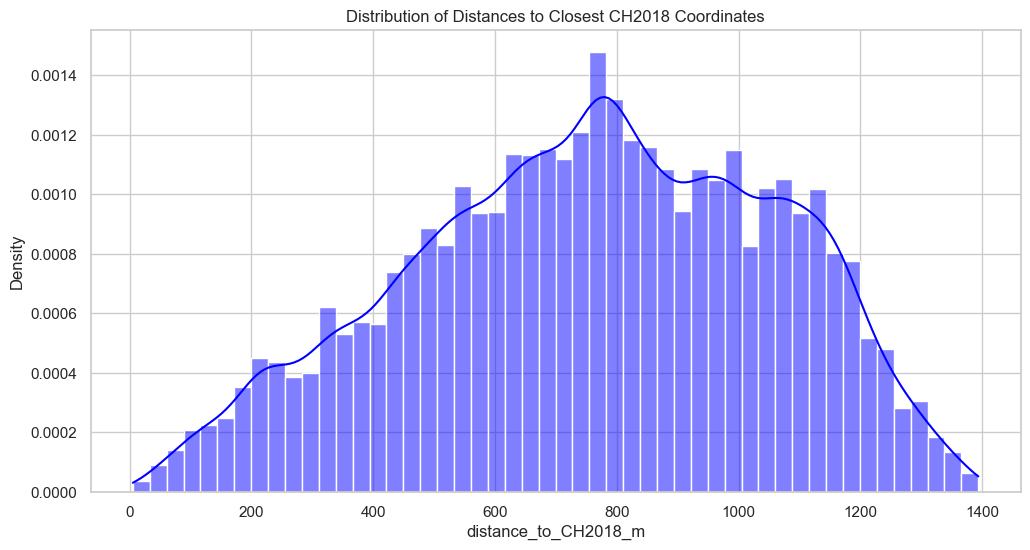

In [72]:
# Matches each NFI plot to its nearest CH2018 climate grid point using a spatial join

NFI_CRS = "EPSG:21781"  # LV03
CH2018_ORIGINAL_CRS = "EPSG:4326" # WGS84 for lat/lon

# --- Load and prepare NFI data ---
print("--- Loading and Preparing NFI Data ---")
nfi_df_initial = pd.read_csv(PROCESSED_NFI_FILE_PATH)
gdf_nfi_full = gpd.GeoDataFrame(
    nfi_df_initial,
    geometry=gpd.points_from_xy(nfi_df_initial['X'].astype(float), nfi_df_initial['Y'].astype(float)),
    crs=NFI_CRS
)

nfi_identifier_cols = ['CLNR', 'INVNR']
gdf_nfi_for_sjoin = gdf_nfi_full[nfi_identifier_cols + ['geometry']].copy()
print(f"NFI data prepared. gdf_nfi_for_sjoin shape: {gdf_nfi_for_sjoin.shape}, CRS: {gdf_nfi_for_sjoin.crs}")

# --- Load CH2018 sample and prepare coordinates in both CRSs ---
print("\n--- Loading Sample CH2018 Data for Coordinates ---")

print(f"Using sample CH2018 file: {SAMPLE_2018_FILE_PATH}")


lon_col_name = 'lon'
lat_col_name = 'lat'

df_ch2018_sample_coords = pd.read_csv(SAMPLE_2018_FILE_PATH, usecols=[lon_col_name, lat_col_name])
df_ch2018_sample_coords.drop_duplicates(inplace=True)
df_ch2018_sample_coords.reset_index(drop=True, inplace=True) # Ensure clean index for alignment



# CH2018 coordinates in their original CRS (EPSG:4326)
gdf_ch2018_sample_4326 = gpd.GeoDataFrame(
    df_ch2018_sample_coords.copy(), # Use a copy to avoid modifying df_ch2018_sample_coords if needed elsewhere
    geometry=gpd.points_from_xy(df_ch2018_sample_coords[lon_col_name], df_ch2018_sample_coords[lat_col_name]),
    crs=CH2018_ORIGINAL_CRS
)
gdf_ch2018_sample_4326['CH2018_lon_4326'] = gdf_ch2018_sample_4326.geometry.x
gdf_ch2018_sample_4326['CH2018_lat_4326'] = gdf_ch2018_sample_4326.geometry.y
print(f"Loaded {len(gdf_ch2018_sample_4326)} unique CH2018 coordinates (EPSG:4326).")

# CH2018 coordinates transformed to NFI CRS (EPSG:21781) for spatial join
gdf_ch2018_sample_21781 = gdf_ch2018_sample_4326.to_crs(NFI_CRS)
gdf_ch2018_sample_21781['CH2018_X_21781'] = gdf_ch2018_sample_21781.geometry.x
gdf_ch2018_sample_21781['CH2018_Y_21781'] = gdf_ch2018_sample_21781.geometry.y
print(f"CH2018 coordinates transformed to CRS: {gdf_ch2018_sample_21781.crs}")


# --- Find closest CH2018 point for each NFI point ---
print("\n--- Finding Closest CH2018 Coordinates for NFI Points ---")

# We only need 'index_right' and 'distance' from this join.
gdf_nfi_with_closest_info = gpd.sjoin_nearest(
    gdf_nfi_for_sjoin,
    gdf_ch2018_sample_21781[['geometry', 'CH2018_X_21781', 'CH2018_Y_21781','CH2018_lon_4326','CH2018_lat_4326']], # Join only necessary cols from right, 
    distance_col="distance_to_CH2018_m" # Distance will be in meters (units of NFI_CRS)
)


gdf_nfi_for_sjoin['distance_to_CH2018_m'] = gdf_nfi_with_closest_info['distance_to_CH2018_m']

gdf_nfi_for_sjoin['closest_CH2018_X_21781'] = gdf_nfi_with_closest_info['CH2018_X_21781']
gdf_nfi_for_sjoin['closest_CH2018_Y_21781'] = gdf_nfi_with_closest_info['CH2018_Y_21781']
gdf_nfi_for_sjoin['closest_CH2018_lon_4326'] = gdf_nfi_with_closest_info['CH2018_lon_4326']
gdf_nfi_for_sjoin['closest_CH2018_lat_4326'] = gdf_nfi_with_closest_info['CH2018_lat_4326']




print("\n--- NFI Data with Original NFI Coords (EPSG:21781) and Closest CH2018 Coords (EPSG:4326 & EPSG:21781) ---")
print(gdf_nfi_for_sjoin.head())
print(f"Shape of updated gdf_nfi_for_sjoin: {gdf_nfi_for_sjoin.shape}")
print(f"Columns: {gdf_nfi_for_sjoin.columns.tolist()}")
print(f"NFI Geometry CRS: {gdf_nfi_for_sjoin.crs}") # Should still be NFI_CRS



sns.set(style="whitegrid")
plt.figure(figsize=(12, 6))
sns.histplot(gdf_nfi_for_sjoin["distance_to_CH2018_m"], bins=50, kde=True, color='blue', stat='density')
plt.title("Distribution of Distances to Closest CH2018 Coordinates")  


print(f"Columns: {gdf_nfi_for_sjoin.columns.tolist()}")
nfi_df_closest_grid = nfi_df_initial.merge(
    gdf_nfi_for_sjoin[['CLNR', 'INVNR', 'closest_CH2018_lon_4326', 'closest_CH2018_lat_4326',"distance_to_CH2018_m"]],
    on=['CLNR', 'INVNR'],
    how='left'
)


print("\n--- Final NFI Data with Closest CH2018 Coordinates ---")
print(nfi_df_closest_grid.head())

nfi_df_closest_grid.to_csv(CLOSEST_COORDS_FILE_PATH, index=False, encoding='utf-8', float_format='%.4f')

print(f"Using sample CH2018 file: {'../data/preprocessed/NFI_CH2018_closest_coords.csv'}")

print( nfi_df_closest_grid['CLNR'].nunique())